In [ ]:
# Loading in the datasets
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns

# machine learning models
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Dropout

# Model management
from sklearn import metrics
from sklearn.preprocessing import StandardScaler
from sklearn.multioutput import MultiOutputRegressor

%matplotlib inline

In [ ]:
# Loading in the dataset
data = pd.read_csv('NBA_Modelling_New.csv')
wnba_data = pd.read_csv('WNBA_Modelling_New.csv')

In [ ]:
# Previewing the dataset
data.head()

,Player,Pos,Age,G,MP,PER,TS%,3PAr,FTr,ORB%,...,PTS,WEIGHT,GP,Height_cm,Draft_status,Years Since Draft,PF,PG,SF,SG
0,Precious Achiuwa,C,24,25,437,15.0,0.512,0.276,0.247,12.3,...,7.7,243.0,74.0,207.264,1.0,3.0,0,0,0,0
1,Precious Achiuwa,PF,24,49,1187,14.5,0.564,0.167,0.234,13.3,...,7.6,243.0,74.0,207.264,1.0,3.0,1,0,0,0
2,Bam Adebayo,C,26,71,2416,19.8,0.576,0.041,0.381,7.4,...,19.3,255.0,71.0,210.312,1.0,6.0,0,0,0,0
3,Ochai Agbaji,SG,23,51,1003,8.1,0.531,0.570,0.080,3.9,...,5.4,215.0,78.0,198.120,1.0,1.0,0,0,0,1
4,Ochai Agbaji,SG,23,27,638,7.1,0.453,0.375,0.196,6.6,...,6.7,215.0,78.0,198.120,1.0,1.0,0,0,0,1


In [ ]:
wnba_data.head()

,Player,Pos,G,MP,PER,TS%,eFG%,3PAr,FTr,ORB%,...,Season,PTS,Age,WEIGHT,GP,Height_cm,PF,PG,SF,SG
0,Lindsay Allen,PG,40,950,12.0,0.537,0.498,0.215,0.233,1.5,...,2023-24,6.6,29,145,40,192.0240,0,1,0,0
1,Rebecca Allen,SG,18,447,10.9,0.522,0.520,0.556,0.024,3.5,...,2023-24,7.4,31,162,18,198.1200,0,0,0,1
2,Laeticia Amihere,PF,16,83,3.5,0.284,0.269,0.000,0.654,16.0,...,2023-24,1.2,23,185,17,186.2328,1,0,0,0
3,Ariel Atkins,PG,40,1196,15.9,0.552,0.516,0.445,0.199,3.5,...,2023-24,14.9,28,167,40,213.3600,0,1,0,0
4,Amy Atwell,PF,6,59,8.3,0.436,0.367,0.867,0.333,6.1,...,2023-24,2.5,26,165,6,210.3120,1,0,0,0


In [ ]:
# Showing the fileds
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2271 entries, 0 to 2270
Data columns (total 36 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Player             2271 non-null   object 
 1   Pos                2271 non-null   object 
 2   Age                2271 non-null   int64  
 3   G                  2271 non-null   int64  
 4   MP                 2271 non-null   int64  
 5   PER                2271 non-null   float64
 6   TS%                2271 non-null   float64
 7   3PAr               2271 non-null   float64
 8   FTr                2271 non-null   float64
 9   ORB%               2271 non-null   float64
 10  DRB%               2271 non-null   float64
 11  TRB%               2271 non-null   float64
 12  AST%               2271 non-null   float64
 13  STL%               2271 non-null   float64
 14  BLK%               2271 non-null   float64
 15  TOV%               2271 non-null   float64
 16  USG%               2271 

In [ ]:
data.drop(columns=[ 'DRB%', 'OBPM', 'DBPM', 'BPM', 'VORP', 'Player', 'Pos', 'WS/48', 'Draft_status', 'Years Since Draft'], inplace=True)

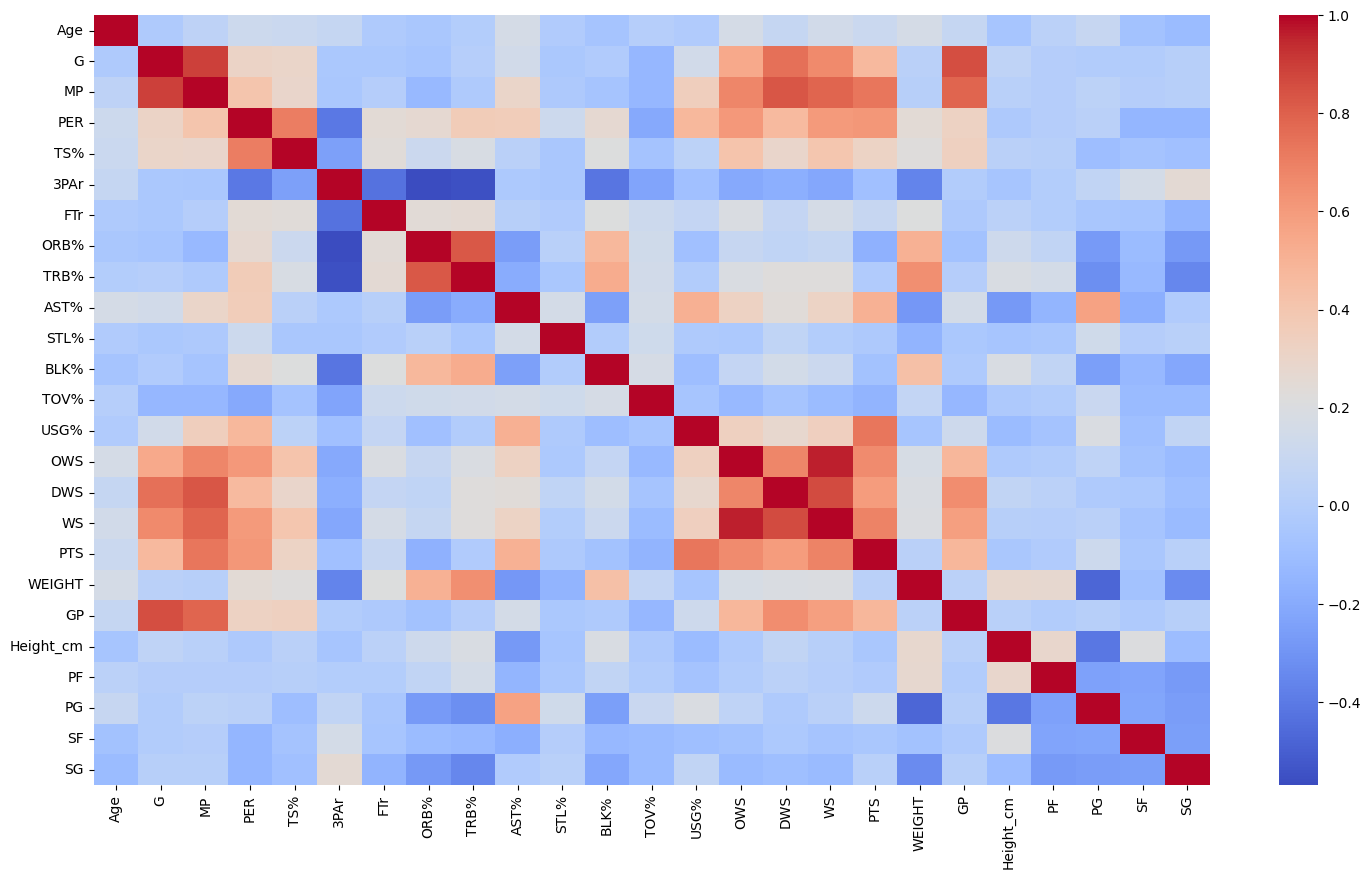

In [ ]:
# Checking for correlation between features
plt.figure(figsize=(18, 10))
corr_matrix = data.select_dtypes(exclude='object').corr()
sns.heatmap(corr_matrix, cmap='coolwarm');

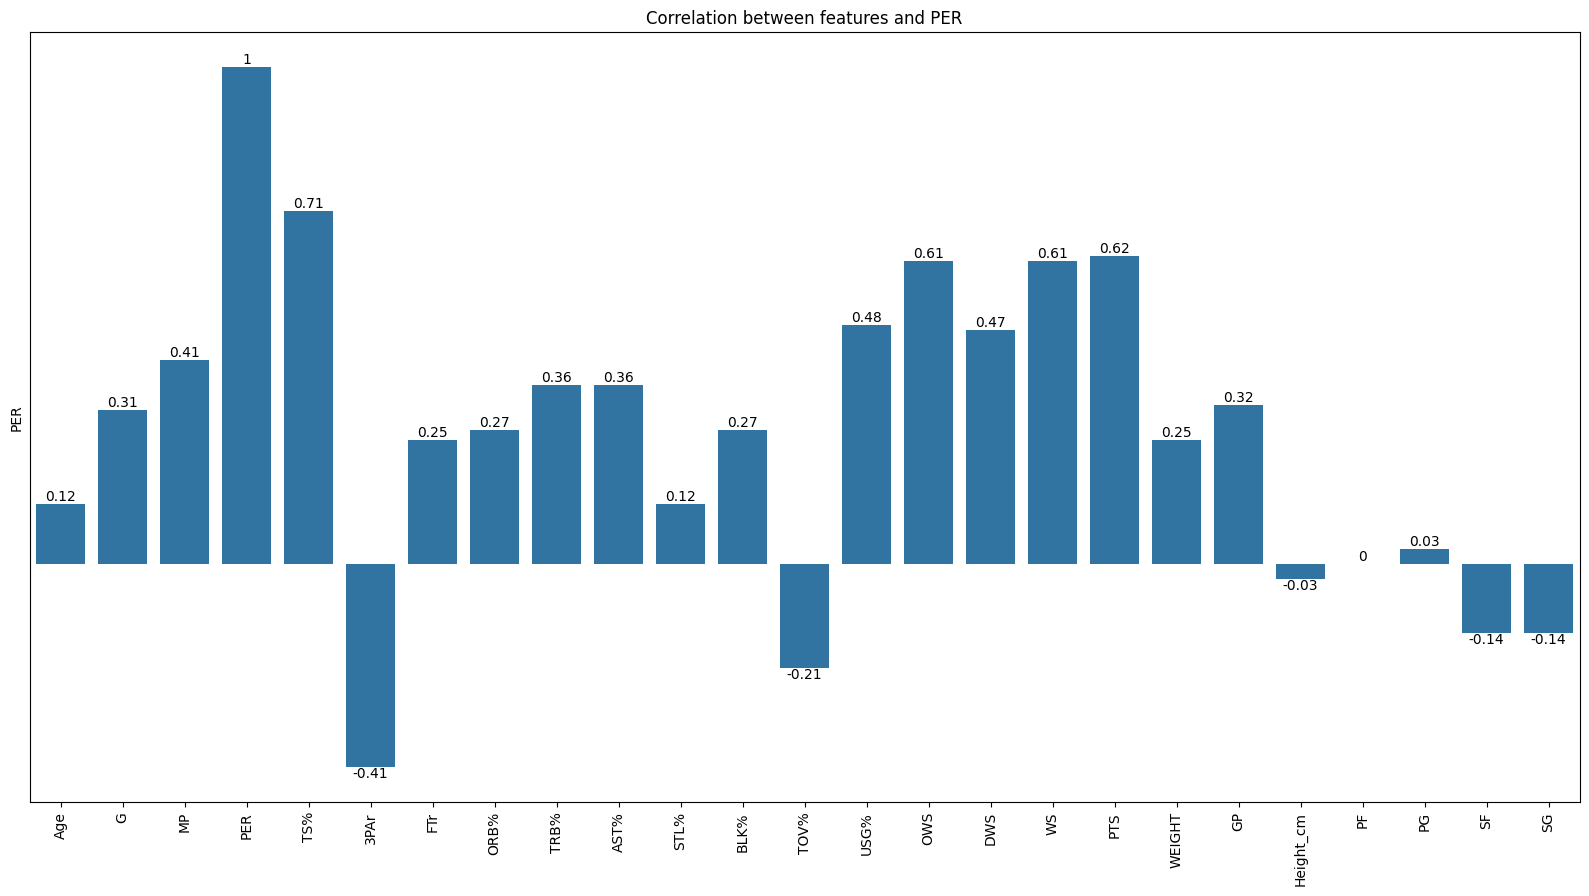

In [ ]:
# Plotting the correlation between features and PER
plt.figure(figsize=(20, 10))
ax = sns.barplot(np.round(corr_matrix['PER'], 2))
ax.bar_label(ax.containers[0])
plt.title('Correlation between features and PER');
plt.xticks(rotation=90)
plt.yticks([]);

## Single Target Approach
This approach will use the PER field as the target variable

In [ ]:
# Showing the seasons in the dataset
data['Season'].unique()

array(['2023-24', '2022-23', '2021-22', '2020-21', '2019-20'],
      dtype=object)

In [ ]:
data.keys()

Index(['Age', 'G', 'MP', 'PER', 'TS%', '3PAr', 'FTr', 'ORB%', 'TRB%', 'AST%',
       'STL%', 'BLK%', 'TOV%', 'USG%', 'OWS', 'DWS', 'WS', 'Season', 'PTS',
       'WEIGHT', 'GP', 'Height_cm', 'PF', 'PG', 'SF', 'SG'],
      dtype='object')

In [ ]:
data.head()

,Age,G,MP,PER,TS%,3PAr,FTr,ORB%,TRB%,AST%,...,WS,Season,PTS,WEIGHT,GP,Height_cm,PF,PG,SF,SG
0,24,25,437,15.0,0.512,0.276,0.247,12.3,17.1,14.5,...,0.4,2023-24,7.7,243.0,74.0,207.264,0,0,0,0
1,24,49,1187,14.5,0.564,0.167,0.234,13.3,16.6,6.2,...,3.0,2023-24,7.6,243.0,74.0,207.264,1,0,0,0
2,26,71,2416,19.8,0.576,0.041,0.381,7.4,17.3,18.9,...,7.2,2023-24,19.3,255.0,71.0,210.312,0,0,0,0
3,23,51,1003,8.1,0.531,0.570,0.080,3.9,6.9,6.1,...,0.4,2023-24,5.4,215.0,78.0,198.120,0,0,0,1
4,23,27,638,7.1,0.453,0.375,0.196,6.6,7.8,7.4,...,-0.3,2023-24,6.7,215.0,78.0,198.120,0,0,0,1


In [ ]:
# Getting the features
features = data.drop(columns = ['PER', 'Season', 'WS']).keys()

# Getting a copy of the dataset
data_one = data.copy()

# scaling the features
StandardScaler_model = StandardScaler()
data_one[features] = StandardScaler_model.fit_transform(data_one[features])

In [ ]:
# splitting the dataset into train and test using season
data_train = data_one[data_one['Season'] != '2023-24'].drop(columns=['Season', 'WS'])
data_test = data_one[data_one['Season'] == '2023-24'].drop(columns=['Season', 'WS'])

In [ ]:
# instantiating the models
RandomForestRegressor_model = RandomForestRegressor()
SVR_model = SVR()

In [ ]:
# Getting the target variable
target = ['PER']

# training the models
RandomForestRegressor_model.fit(data_train.drop(target, axis=1), data_train[target])
SVR_model.fit(data_train.drop(target, axis=1), data_train[target])

/usr/local/lib/python3.10/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/usr/local/lib/python3.10/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


SVR()

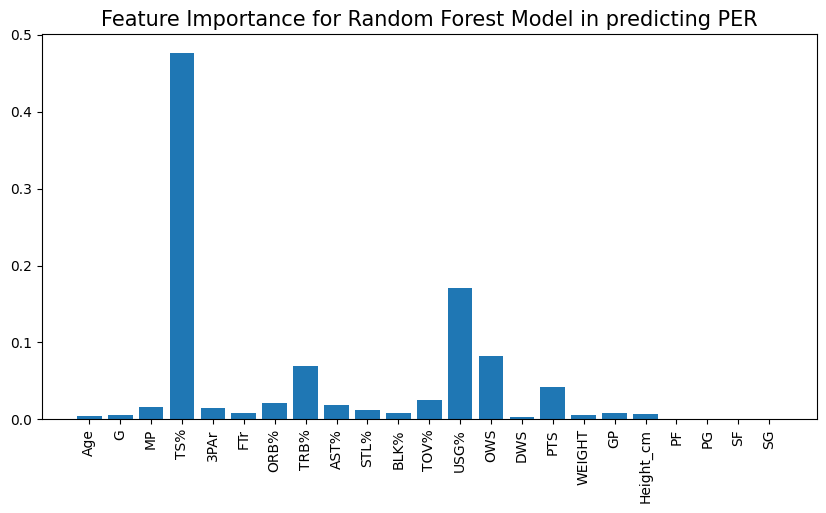

In [ ]:
plt.figure(figsize=(10, 5))
plt.title('Feature Importance for Random Forest Model in predicting PER', size=15)
plt.bar(features, RandomForestRegressor_model.feature_importances_)
plt.xticks(rotation=90);

In [ ]:
# Building the dataset fo the RNN model
data_train_rnn = np.reshape(data_train.drop(columns=['PER']).values, (data_train.shape[0], 1, data_train.shape[1] - 1))
data_test_rnn = np.reshape(data_test.drop(columns=['PER']).values, (data_test.shape[0], 1, data_test.shape[1] - 1))

# Getting the target data in shape
per_train_rnn = data_train['PER'].values
per_test_rnn = data_test['PER'].values

In [ ]:
# Create the model
model = Sequential([
    # First RNN layer with return_sequences=True
    SimpleRNN(64, activation='tanh', return_sequences=True, input_shape=(1, data_train.shape[1] - 1)),
    SimpleRNN(64, activation='tanh', return_sequences=True),
    SimpleRNN(64, activation='tanh'),
    Dense(1)  # Output layer for regression
])

# Compile the model
model.compile(optimizer='adam', loss='mse', metrics=['mse'])  # MAPE for regression

# Fitting the model
history = model.fit(data_train_rnn, per_train_rnn, epochs=20, batch_size=32, validation_split=0.2)

Epoch 1/20


/usr/local/lib/python3.10/dist-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


46/46 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - loss: 222.0679 - mse: 222.0679 - val_loss: 156.4463 - val_mse: 156.4463
Epoch 2/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 131.9608 - mse: 131.9608 - val_loss: 30.9545 - val_mse: 30.9545
Epoch 3/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 24.1324 - mse: 24.1324 - val_loss: 12.3936 - val_mse: 12.3936
Epoch 4/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 11.6616 - mse: 11.6616 - val_loss: 10.1312 - val_mse: 10.1312
Epoch 5/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 11.7424 - mse: 11.7424 - val_loss: 8.4791 - val_mse: 8.4791
Epoch 6/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 12.1138 - mse: 12.1138 - val_loss: 7.4191 - val_mse: 7.4191
Epoch 7/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 9.1730 - mse: 9.1730 - val_loss: 6.4687 - val_mse: 6.4687
Epoch 8/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 10.4144 - mse: 10.4144 - val_loss: 5.5509 - val_mse: 5.5509
Epoch 9/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - lo

In [ ]:
# Predicting the results using the trained model
random_forest_pred = RandomForestRegressor_model.predict(data_test.drop(target, axis=1))
SVR_pred = SVR_model.predict(data_test.drop(target, axis=1))
RNN_pred = model.predict(data_test_rnn)

15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step


## Evaluating the Model
- Mean Absolute Percentage Error
- Mean Squared Error

In [ ]:
rmse_randomforest = np.sqrt(metrics.mean_squared_error(data_test['PER'], random_forest_pred))
rmse_svr = np.sqrt(metrics.mean_squared_error(data_test['PER'], SVR_pred))
rmse_rnn = np.sqrt(metrics.mean_squared_error(per_test_rnn, RNN_pred))

mae_randomforest = metrics.mean_absolute_error(data_test['PER'], random_forest_pred)
mae_svr = metrics.mean_absolute_error(data_test['PER'], SVR_pred)
mae_rnn = metrics.mean_absolute_error(per_test_rnn, RNN_pred)

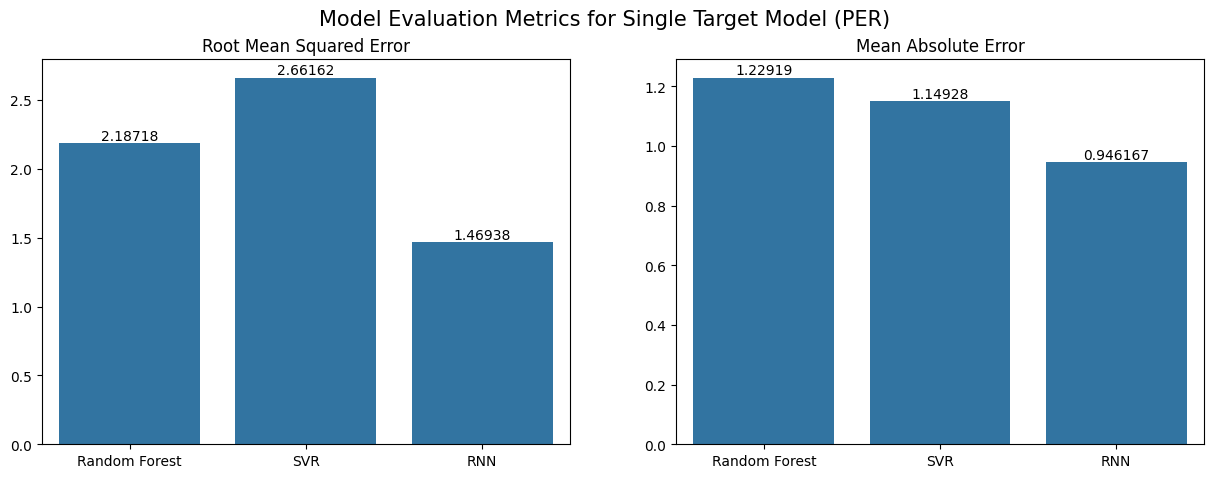

In [ ]:
# Saving the results to compare the MAPE
results = {'Random Forest': rmse_randomforest, 'SVR': rmse_svr, 'RNN': rmse_rnn}

plt.figure(figsize=(15, 5))
plt.suptitle('Model Evaluation Metrics for Single Target Model (PER)', size=15)
plt.subplot(1, 2, 1)
ax = sns.barplot(x=list(results.keys()), y=list(results.values()))
ax.bar_label(ax.containers[0])
plt.title('Root Mean Squared Error');

plt.subplot(1, 2, 2)
ax = sns.barplot(x=list(results.keys()), y=[mae_randomforest, mae_svr, mae_rnn])
ax.bar_label(ax.containers[0])
plt.title('Mean Absolute Error');

## Multi-Target Approach

In [ ]:
# Saving a copy of the dataset to variable
data_two = data.copy()

# Getting the multi output target
targets = ['PER', 'WS']

# Getting the features for the multi-target approach
features_two = data_two.drop(columns = ['PER',  'WS', 'Season', 'OWS', 'DWS']).keys()

# scaling the features
data_two[features_two] = StandardScaler_model.fit_transform(data_two[features_two])

# splitting the dataset into train and test using season
data_train_2 = data_two[data_two['Season'] != '2023-24'].drop(columns=['Season', 'OWS', 'DWS'])
data_test_2 = data_two[data_two['Season'] == '2023-24'].drop(columns=['Season', 'OWS', 'DWS'])

In [ ]:
# Wrapping the model with a multi regressor output
MultiForest_model = MultiOutputRegressor(RandomForestRegressor())
MultiSVR_model = MultiOutputRegressor(SVR())

# Fitting the data to the multi output model
MultiForest_model.fit(data_train_2.drop(targets, axis=1), data_train_2[targets])
MultiSVR_model.fit(data_train_2.drop(targets, axis=1), data_train_2[targets])

MultiOutputRegressor(estimator=SVR())

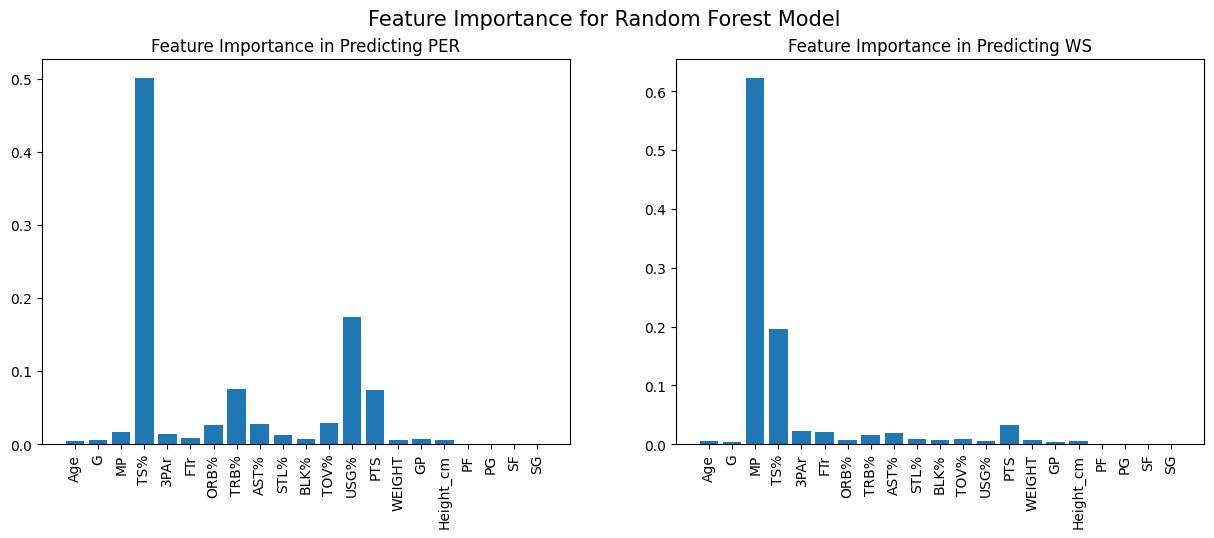

In [ ]:
plt.figure(figsize=(15, 5))
plt.suptitle('Feature Importance for Random Forest Model', size=15)

plt.subplot(1, 2, 1)
plt.title('Feature Importance in Predicting PER')
plt.bar(features_two, MultiForest_model.estimators_[0].feature_importances_)
plt.xticks(rotation=90)

plt.subplot(1, 2, 2)
plt.title('Feature Importance in Predicting WS')
plt.bar(features_two, MultiForest_model.estimators_[1].feature_importances_)
plt.xticks(rotation=90);

In [ ]:
# Building the dataset fo the RNN model
data_train_2_rnn = np.reshape(data_train_2.drop(columns=targets).values, (data_train_2.shape[0], 1, data_train_2.shape[1] - 2))
data_test_2_rnn = np.reshape(data_test_2.drop(columns=targets).values, (data_test_2.shape[0], 1, data_test_2.shape[1] - 2))

# Getting the target data in shape
per_train_2_rnn = data_train_2[targets].values
per_test_2_rnn = data_test_2[targets].values

# Create the model
MultiRNN_model = Sequential([
    # First RNN layer with return_sequences=True
    SimpleRNN(64, activation='tanh', return_sequences=True, input_shape=(1, data_train_2.shape[1] - 2)),
    SimpleRNN(64, activation='tanh', return_sequences=True),
    SimpleRNN(64, activation='tanh'),
    Dense(2)  # Output layer for regression
])

# Compile the model
MultiRNN_model.compile(optimizer='adam', loss='mse', metrics=['mse'])  # MSE for regression

# Fitting the model
MultiRNN_history = MultiRNN_model.fit(data_train_2_rnn, per_train_2_rnn, epochs=20, batch_size=32, validation_split=0.2)

Epoch 1/20


/usr/local/lib/python3.10/dist-packages/keras/src/layers/rnn/rnn.py:204: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


46/46 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - loss: 109.0303 - mse: 109.0303 - val_loss: 76.1588 - val_mse: 76.1588
Epoch 2/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 59.0569 - mse: 59.0569 - val_loss: 13.7807 - val_mse: 13.7807
Epoch 3/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 10.6771 - mse: 10.6771 - val_loss: 7.6622 - val_mse: 7.6622
Epoch 4/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 9.9495 - mse: 9.9495 - val_loss: 6.4284 - val_mse: 6.4284
Epoch 5/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 10.3814 - mse: 10.3814 - val_loss: 5.5420 - val_mse: 5.5420
Epoch 6/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 5.7873 - mse: 5.7873 - val_loss: 4.9554 - val_mse: 4.9554
Epoch 7/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 5.9606 - mse: 5.9606 - val_loss: 4.3848 - val_mse: 4.3848
Epoch 8/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 9.5764 - mse: 9.5764 - val_loss: 3.9001 - val_mse: 3.9001
Epoch 9/20
46/46 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 5.6706 - m

In [ ]:
# Predicting the results using the trained model
random_forest_pred_2 = MultiForest_model.predict(data_test_2.drop(targets, axis=1))
SVR_pred_2 = MultiSVR_model.predict(data_test_2.drop(targets, axis=1))
RNN_pred_2 = MultiRNN_model.predict(data_test_2_rnn)

15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step


In [ ]:
rmse_randomforest_per = np.sqrt(metrics.mean_squared_error(data_test_2[targets[0]], random_forest_pred_2[:, 0]))
rmse_svr_per = np.sqrt(metrics.mean_squared_error(data_test_2[targets[0]], SVR_pred_2[:, 0]))
rmse_rnn_per = np.sqrt(metrics.mean_squared_error(per_test_2_rnn[:, 0], RNN_pred_2[:, 0]))

rmse_randomforest_ws = np.sqrt(metrics.mean_squared_error(data_test_2[targets[1]], random_forest_pred_2[:, 1]))
rmse_svr_ws = np.sqrt(metrics.mean_squared_error(data_test_2[targets[1]], SVR_pred_2[:, 1]))
rmse_rnn_ws = np.sqrt(metrics.mean_squared_error(per_test_2_rnn[:, 1], RNN_pred_2[:, 1]))

In [ ]:
mae_randomforest_per = metrics.mean_absolute_error(data_test_2[targets[0]], random_forest_pred_2[:, 0])
mae_svr_per = metrics.mean_absolute_error(data_test_2[targets[0]], SVR_pred_2[:, 0])
mae_rnn_per = metrics.mean_absolute_error(per_test_2_rnn[:, 0], RNN_pred_2[:, 0])

mae_randomforest_ws = metrics.mean_absolute_error(data_test_2[targets[1]], random_forest_pred_2[:, 1])
mae_svr_ws = metrics.mean_absolute_error(data_test_2[targets[1]], SVR_pred_2[:, 1])
mae_rnn_ws = metrics.mean_absolute_error(per_test_2_rnn[:, 1], RNN_pred_2[:, 1])

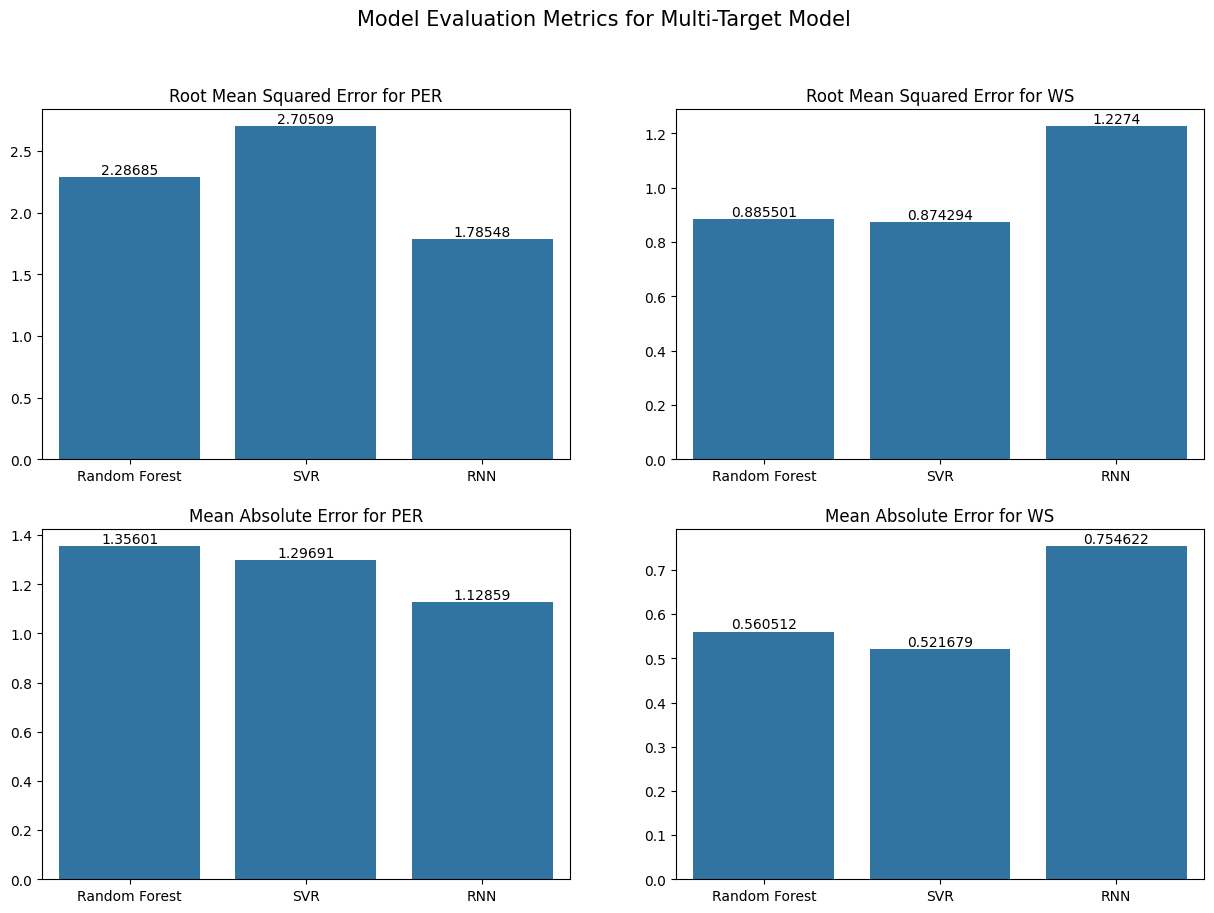

In [ ]:
# Saving the results to compare the MAPE
results = {'Random Forest': rmse_randomforest, 'SVR': rmse_svr, 'RNN': rmse_rnn}

plt.figure(figsize=(15, 10))
plt.suptitle('Model Evaluation Metrics for Multi-Target Model', size=15)
plt.subplot(2, 2, 1)
ax = sns.barplot(x=list(results.keys()), y=[rmse_randomforest_per, rmse_svr_per, rmse_rnn_per])
ax.bar_label(ax.containers[0])
plt.title('Root Mean Squared Error for PER');

plt.subplot(2, 2, 2)
ax = sns.barplot(x=list(results.keys()), y=[rmse_randomforest_ws, rmse_svr_ws, rmse_rnn_ws])
ax.bar_label(ax.containers[0])
plt.title('Root Mean Squared Error for WS');

plt.subplot(2, 2, 3)
ax = sns.barplot(x=list(results.keys()), y=[mae_randomforest_per, mae_svr_per, mae_rnn_per])
ax.bar_label(ax.containers[0])
plt.title('Mean Absolute Error for PER');

plt.subplot(2, 2, 4)
ax = sns.barplot(x=list(results.keys()), y=[mae_randomforest_ws, mae_svr_ws, mae_rnn_ws])
ax.bar_label(ax.containers[0])
plt.title('Mean Absolute Error for WS');

### Testing on the WNBA Dataset

Given that the RNN model was the best performing model. It will be used for the WNBA dataset

In [ ]:
 # Removing the null values
wnba_data[features] = wnba_data[features].replace('-', np.nan)

# Removing null values
wnba_data.dropna(inplace=True)

In [ ]:
# Preparing the dataset
wnba_copy_1 = pd.DataFrame(StandardScaler_model.fit_transform(wnba_data[features]), columns = features)
wnba_copy_2 = pd.DataFrame(StandardScaler_model.fit_transform(wnba_data[features_two]), columns = features_two)

# Preparing the dataset for the single target model
wnba_rnn_1 = np.reshape(wnba_copy_1.values, (wnba_copy_1.shape[0], 1, wnba_copy_1.shape[1]))
wnba_rnn_target_1 = wnba_data['PER'].values

# Preparing the dataset for the multi-target model
wnba_rnn_2 = np.reshape(wnba_copy_2.values, (wnba_copy_2.shape[0], 1, wnba_copy_2.shape[1]))
wnba_rnn_target_2 = wnba_data['PER'].values

In [ ]:
# Predict using the WNBA dataset
wnba_pred_1 = model.predict(wnba_rnn_1)
wnba_pred_2 = MultiRNN_model.predict(wnba_rnn_2)

26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


In [ ]:
# Evaluation metrics
wnba_mae = metrics.mean_absolute_error(wnba_rnn_target_1, wnba_pred_1)
wnba_rmse = np.sqrt(metrics.mean_squared_error(wnba_rnn_target_1, wnba_pred_1))

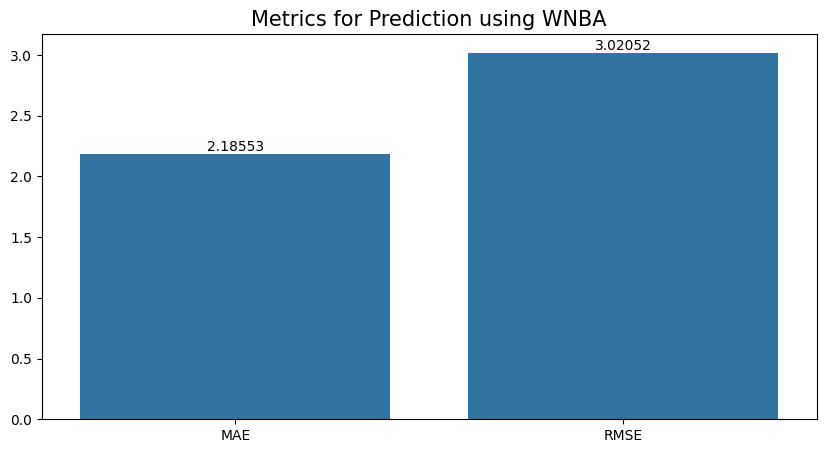

In [ ]:
plt.figure(figsize=(10, 5))
plt.title('Metrics for Prediction using WNBA', size=15)
ax = sns.barplot(x = ['MAE', 'RMSE'], y=[wnba_mae, wnba_rmse]);
ax.bar_label(ax.containers[0]);

In [ ]:
wnba_mae_per = metrics.mean_absolute_error(wnba_data['PER'].values, wnba_pred_2[:, 0])
wnba_rmse_per = np.sqrt(metrics.mean_squared_error(wnba_data['PER'].values, wnba_pred_2[:, 0]))

# Getting the metrics for win share
wnba_mae_ws = metrics.mean_absolute_error(wnba_data['WS'].values, wnba_pred_2[:, 1])
wnba_rmse_ws = np.sqrt(metrics.mean_squared_error(wnba_data['WS'].values, wnba_pred_2[:, 1]))

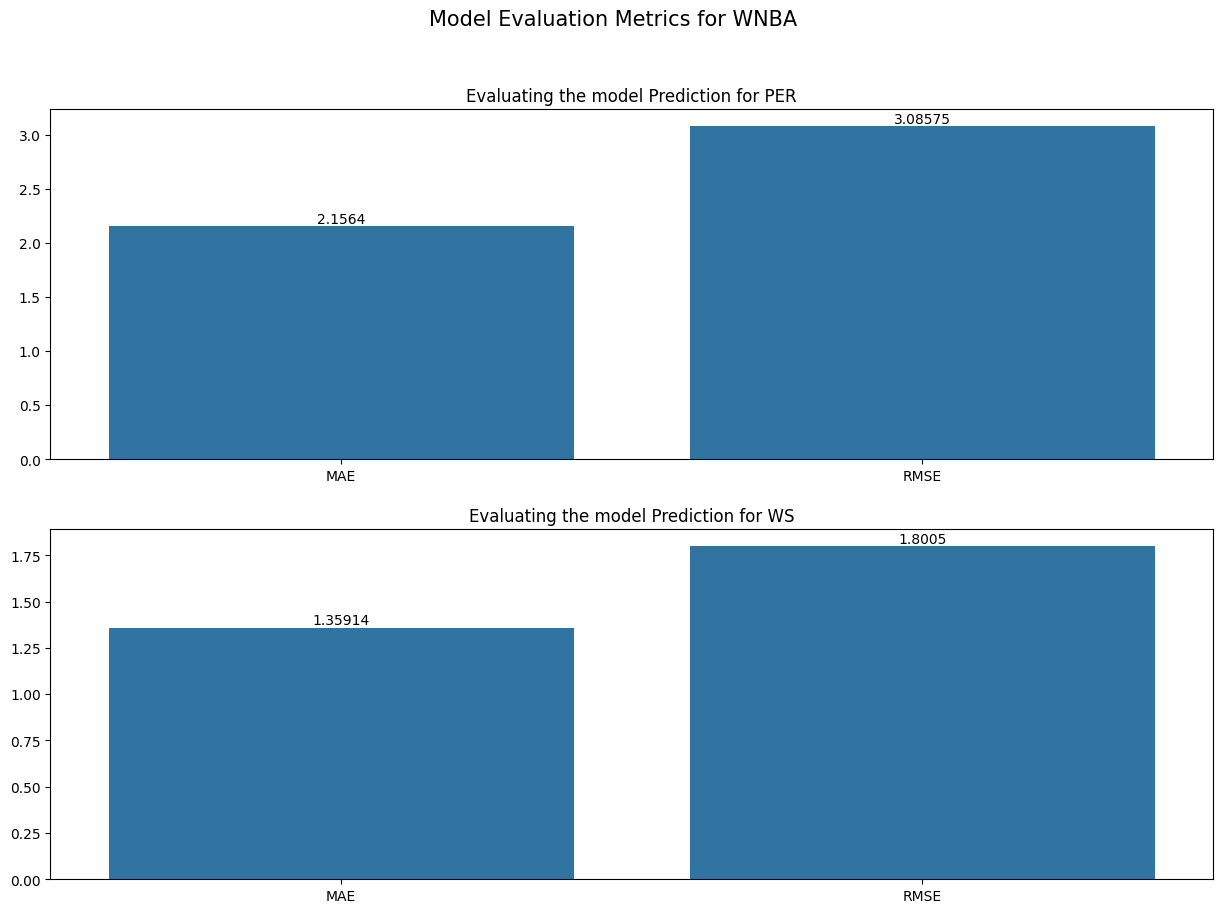

In [ ]:
# Plotting the graph of PER and WS

plt.figure(figsize=(15, 10))
plt.suptitle('Model Evaluation Metrics for WNBA', size=15)

plt.subplot(2, 1, 1)
ax = sns.barplot(x = ['MAE', 'RMSE'], y=[wnba_mae_per, wnba_rmse_per]);
ax.bar_label(ax.containers[0]);
plt.title('Evaluating the model Prediction for PER')

plt.subplot(2, 1, 2)
ax = sns.barplot(x = ['MAE', 'RMSE'], y=[wnba_mae_ws, wnba_rmse_ws]);
ax.bar_label(ax.containers[0])
plt.title('Evaluating the model Prediction for WS');

In [ ]:
# top_five_players_2024 =
top_five = wnba_data[wnba_data['Player'].isin(["A'Ja Wilson", 'Breanna Stewart', 'Alyssa Thomas', 'Jonquel Jones', 'Napheesa Collier'])]

# Getting the top five in 2024
top_five_2024 = top_five[top_five['Season'] == '2023-24']

In [ ]:
# Reshaping the dataset
test_wnba_data = StandardScaler_model.fit_transform(top_five_2024[features]).reshape(top_five_2024.shape[0], 1, len(features))

In [ ]:
# Predicted PER for Top 5
pred_per_top_5 = model.predict(test_wnba_data)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step


In [ ]:
# Assigning the predicted PER back to the dataframe
top_five_2024['Predicted PER'] = pred_per_top_5

<ipython-input-40-3f9956ce719a>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  top_five_2024['Predicted PER'] = pred_per_top_5


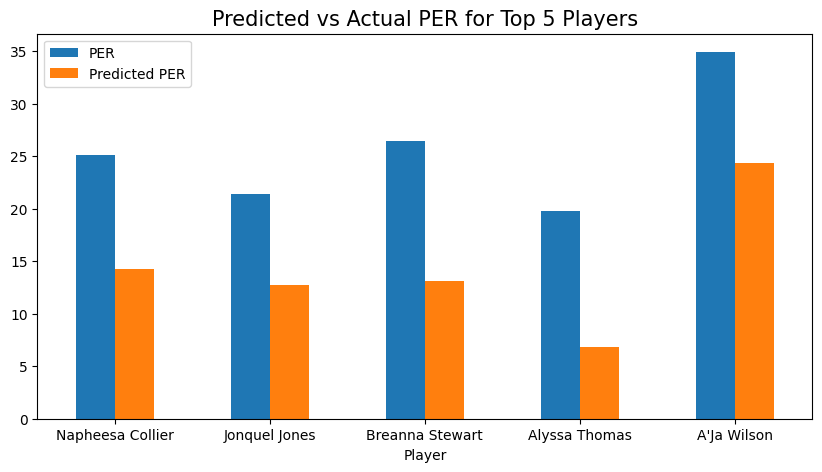

In [ ]:
# plotting the predicted and actual PER side by side
top_five_2024.plot(x='Player', y=['PER', 'Predicted PER'], kind='bar', figsize=(10, 5))
plt.title('Predicted vs Actual PER for Top 5 Players', size=15)
plt.xticks(rotation=0);

In [ ]:
wnba_data['PER'].mean()

12.09620563035496

In [ ]:
wnba_data['WS'].mean()

1.187515299877601